# 16. Прогнозирование иерархических временных рядов

Рабочий ноутбук к главе книги `../chapters/16-hierarchical.md`: здесь только задания и код, теория и выводы — в главе. Источник — глава 32 пособия. Все задания на синтетике: иерархических рядов в наших данных пока нет.

Графики для главы сохраняй через `save_fig(fig, "имя")` → `../chapters/img/16-имя.png`.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Глушим шум до импорта ETNA: FutureWarning из pandas и предупреждение tqdm про ipywidgets
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="IProgress not found")

from etna.datasets import TSDataset
from etna.models import SeasonalMovingAverageModel
from etna.pipeline import HierarchicalPipeline
from etna.reconciliation import BottomUpReconciliator, TopDownReconciliator
from etna.metrics import SMAPE

IMG_DIR = "../chapters/img"  # графики для главы книги
HORIZON = 14
RANDOM_SEED = 42


def save_fig(fig, name: str) -> None:
    """Сохранить график для главы книги: ../chapters/img/16-<name>.png."""
    os.makedirs(IMG_DIR, exist_ok=True)
    fig.savefig(f"{IMG_DIR}/16-{name}.png", dpi=150, bbox_inches="tight")

## Задание 1. Синтетика: как устроена иерархия

Сеть магазинов: всего → регион → магазин.

### Шаг 1.1. Иерархический датасет

Длинная таблица со столбцами `region` и `shop` → `TSDataset.to_hierarchical_dataset` → `TSDataset` с `hierarchical_structure`. Уровни выше собираются суммированием: `get_level_dataset`.

In [2]:
# Сеть из 6 магазинов в 2 регионах, 26 недель дневных заказов: total → region → shop.
# У каждого магазина свой уровень, недельный узор общий (выходные выше будней), шум ±15%
PERIODS = 26 * 7
SHOPS = {"north": {"n1": 150, "n2": 100, "n3": 40}, "south": {"s1": 200, "s2": 80, "s3": 50}}
rng = np.random.RandomState(RANDOM_SEED)
timestamps = pd.date_range("2026-01-05", periods=PERIODS, freq="D")  # начинаем с понедельника
weekly = np.where(timestamps.dayofweek >= 5, 1.3, 0.9)


def make_hierarchy(levels: dict) -> TSDataset:
    """Иерархический TSDataset из словаря {магазин: уровень по дням}."""
    frames = []
    for region, shops in SHOPS.items():
        for shop in shops:
            values = levels[shop] * weekly * (1 + rng.normal(0, 0.15, PERIODS))
            frames.append(pd.DataFrame({"timestamp": timestamps, "region": region, "shop": shop, "target": np.maximum(values, 0).round()}))
    df_wide, structure = TSDataset.to_hierarchical_dataset(df=pd.concat(frames), level_columns=["region", "shop"])
    return TSDataset(df_wide, freq="D", hierarchical_structure=structure)


stable_levels = {shop: np.full(PERIODS, float(level)) for shops in SHOPS.values() for shop, level in shops.items()}
ts_stable = make_hierarchy(stable_levels)
structure = ts_stable.hierarchical_structure
print("уровни:", structure.level_names)
print("связи:", structure.level_structure)
print("текущий уровень датасета:", ts_stable.current_df_level, "| сегменты:", ts_stable.segments)

уровни: ['total', 'region', 'shop']
связи: {'total': ['north', 'south'], 'north': ['north_n1', 'north_n2', 'north_n3'], 'south': ['south_s1', 'south_s2', 'south_s3']}
текущий уровень датасета: shop | сегменты: ['north_n1', 'north_n2', 'north_n3', 'south_s1', 'south_s2', 'south_s3']


north = n1 + n2 + n3: True


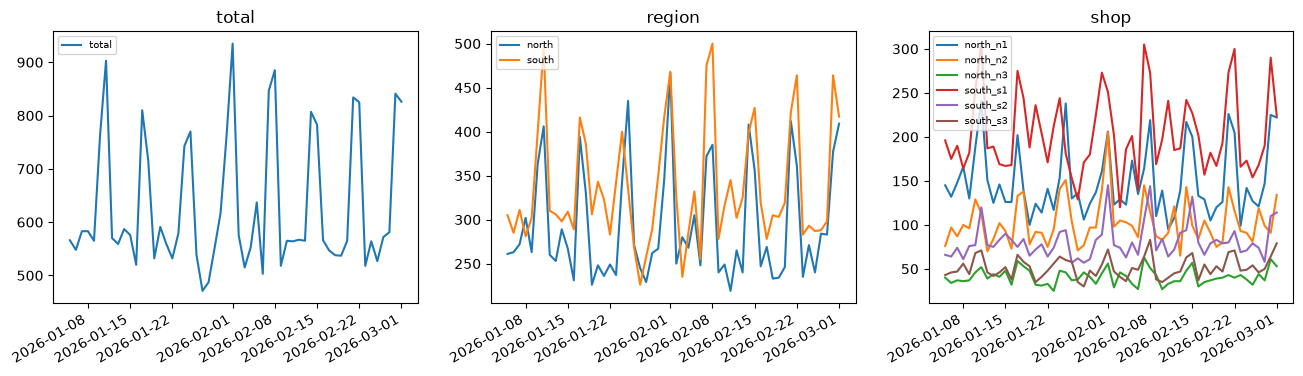

In [3]:
# get_level_dataset суммирует ряды до нужного уровня
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True)
for ax, level in zip(axes, ["total", "region", "shop"]):
    level_ts = ts_stable.get_level_dataset(target_level=level)
    for segment in level_ts.segments:
        ax.plot(timestamps[:56], level_ts[:, segment, "target"].values[:56], label=segment)
    ax.set_title(level)
    ax.legend(loc="upper left", fontsize=7)
fig.autofmt_xdate()
save_fig(fig, "levels")

# Проверка: регион north — это сумма своих трёх магазинов
north_sum = ts_stable[:, ["north_n1", "north_n2", "north_n3"], "target"].sum(axis=1)
print("north = n1 + n2 + n3:", np.allclose(ts_stable.get_level_dataset("region")[:, "north", "target"], north_sum))

#### Выводы

- **Структуру ETNA нашла сама по столбцам:** 3 уровня `total → region → shop`, уровень `total` добавлен автоматически.
- **Сегменты нижнего уровня названы по пути:** `north_n1` — магазин `n1` в регионе `north`.
- **Датасет хранит только нижний уровень** (`current_df_level = shop`), а верхние получаются суммой: `north` в точности равен `n1 + n2 + n3`.

### Шаг 1.2. Реконсиляция

`BottomUpReconciliator` и `TopDownReconciliator` после `fit`: матрица перехода между уровнями `mapping_matrix`.

In [4]:
# Bottom-up: прогнозируем магазины, суммируем до регионов. Матрица — какие магазины в какой регион складываются
bottom_up = BottomUpReconciliator(target_level="region", source_level="shop").fit(ts_stable)
pd.DataFrame(bottom_up.mapping_matrix.toarray(), index=structure.get_level_segments("region"), columns=ts_stable.segments)

,north_n1,north_n2,north_n3,south_s1,south_s2,south_s3
north,1,1,1,0,0,0
south,0,0,0,1,1,1


In [5]:
# Top-down: прогнозируем total, делим на магазины по долям за последние 56 дней. Два способа посчитать долю
proportions = {}
for method in ["AHP", "PHA"]:
    top_down = TopDownReconciliator(target_level="shop", source_level="total", period=56, method=method).fit(ts_stable)
    proportions[method] = top_down.mapping_matrix.toarray().ravel()
pd.DataFrame(proportions, index=ts_stable.segments).round(3)

,AHP,PHA
north_n1,0.242,0.242
north_n2,0.162,0.162
north_n3,0.062,0.061
south_s1,0.317,0.319
south_s2,0.136,0.135
south_s3,0.081,0.081


#### Выводы

- **Bottom-up — матрица из 0 и 1:** регион — сумма своих магазинов. Ничего не оценивается.
- **Top-down — матрица долей:** магазин получает свою долю прогноза `total`. Доли оцениваются по истории за последние `period` дней.
- **AHP и PHA дали почти одинаковые доли** (отличие в третьем знаке): при стабильных долях без нулей способы совпадают. AHP — среднее из ежедневных долей, PHA — доля средних за период.

## Задание 2. Bottom-up против top-down

Какой способ точнее и на каком уровне — когда доли магазинов стабильны и когда меняются.

### Шаг 2.1. Два сценария

`stable` — из задания 1. `shift` — та же сеть, но за последние 60 дней `n3` вырастает с 40 до 160 заказов в день, а `s1` падает с 200 до 110.

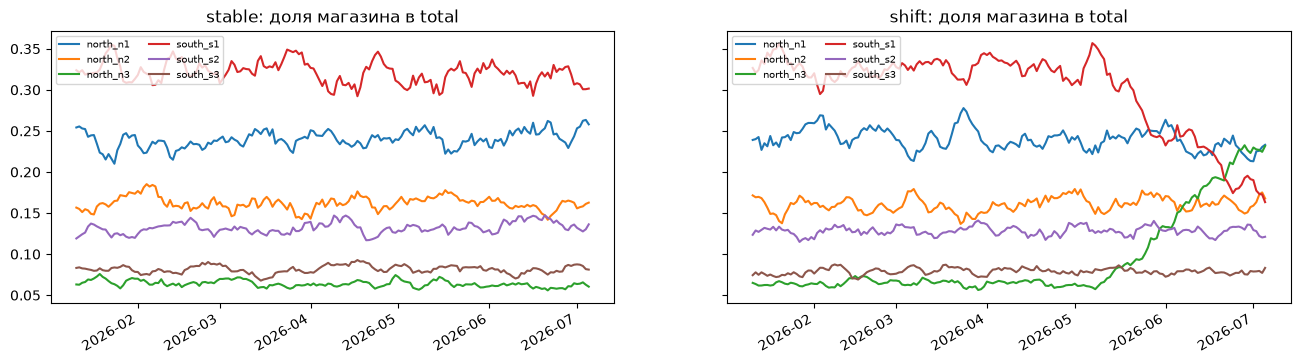

In [6]:
# Второй сценарий — доли меняются: за последние 60 дней магазин n3 вырастает с 40 до 160, а s1 падает с 200 до 110
shift_levels = dict(stable_levels)
t = np.arange(PERIODS)
shift_levels["n3"] = np.interp(t, [0, PERIODS - 60, PERIODS - 1], [40, 40, 160])
shift_levels["s1"] = np.interp(t, [0, PERIODS - 60, PERIODS - 1], [200, 200, 110])
ts_shift = make_hierarchy(shift_levels)

# Доля каждого магазина в total, сглаженная по неделям
fig, axes = plt.subplots(1, 2, figsize=(16, 4), sharey=True)
for ax, (name, ts) in zip(axes, {"stable": ts_stable, "shift": ts_shift}.items()):
    shops = ts[:, :, "target"].droplevel("feature", axis=1)
    share = shops.div(shops.sum(axis=1), axis=0).rolling(7).mean()
    for segment in share.columns:
        ax.plot(share.index, share[segment], label=segment)
    ax.set_title(f"{name}: доля магазина в total")
    ax.legend(loc="upper left", fontsize=7, ncol=2)
fig.autofmt_xdate()
save_fig(fig, "shares")

#### Выводы

- **`stable`:** доли каждого магазина колеблются вокруг одного значения.
- **`shift`:** доля `n3` растёт с 0.06 до 0.23, доля `s1` падает с 0.33 до 0.17. При этом `total` меняется мало: рост `n3` почти покрывает падение `s1`.

### Шаг 2.2. Ошибка по уровням

`HierarchicalPipeline` с каждым способом на каждом уровне: backtest, 3 фолда по 14 дней, модель `SeasonalMovingAverageModel(window=4, seasonality=7)`. Top-down — с долями за 56 и за 7 дней.

In [7]:
# Каждый способ — на каждом уровне: backtest на 3 фолдах по 14 дней, модель — сезонное скользящее среднее за 4 недели
METHODS = {
    "bottom_up": lambda level: BottomUpReconciliator(target_level=level, source_level="shop"),
    "top_down_ahp_56": lambda level: TopDownReconciliator(target_level=level, source_level="total", period=56, method="AHP"),
    "top_down_pha_56": lambda level: TopDownReconciliator(target_level=level, source_level="total", period=56, method="PHA"),
    "top_down_ahp_7": lambda level: TopDownReconciliator(target_level=level, source_level="total", period=7, method="AHP"),
}


def smape_by_level(ts: TSDataset) -> pd.DataFrame:
    """SMAPE, %, средний по сегментам уровня и фолдам: строка — способ, столбец — уровень."""
    result = {}
    for name, make_reconciliator in METHODS.items():
        for level in ["total", "region", "shop"]:
            pipeline = HierarchicalPipeline(
                reconciliator=make_reconciliator(level),
                model=SeasonalMovingAverageModel(window=4, seasonality=7),
                horizon=HORIZON,
            )
            metrics = pipeline.backtest(ts, metrics=[SMAPE()], n_folds=3, joblib_params={"verbose": 0})["metrics"]
            result.setdefault(name, {})[level] = metrics["SMAPE"].mean()
    return pd.DataFrame(result).T.round(2)


errors = pd.concat({"stable": smape_by_level(ts_stable), "shift": smape_by_level(ts_shift)}, axis=1)
errors

stable               shift              
                 total region   shop total region   shop
bottom_up         5.44   7.75  12.60  4.85  12.83  19.25
top_down_ahp_56   5.44   7.11  11.49  4.85  17.58  24.20
top_down_pha_56   5.44   7.09  11.48  4.85  17.56  24.11
top_down_ahp_7    5.44   6.98  11.82  4.85   9.23  15.12

#### Выводы

SMAPE, %:

| способ | stable: total | region | shop | shift: total | region | shop |
|---|---|---|---|---|---|---|
| `bottom_up` | 5.44 | 7.75 | 12.60 | 4.85 | 12.83 | 19.25 |
| `top_down` AHP, 56 дней | 5.44 | 7.11 | 11.49 | 4.85 | 17.58 | 24.20 |
| `top_down` PHA, 56 дней | 5.44 | **7.09** | **11.48** | 4.85 | 17.56 | 24.11 |
| `top_down` AHP, 7 дней | 5.44 | **6.98** | 11.82 | 4.85 | **9.23** | **15.12** |

- **На уровне `total` все способы совпали.** Скользящее среднее линейно: сумма прогнозов магазинов в точности равна прогнозу суммы.
- **`stable`: top-down точнее на нижних уровнях** — 11.5 против 12.6 у магазинов. `total` меньше шумит, а доли стабильны, поэтому разделить хороший прогноз суммы по долям лучше, чем прогнозировать каждый шумный магазин отдельно.
- **`shift`: top-down с долями за 56 дней — худший** (24.2 у магазинов). Доли 8-недельной давности не знают, что `n3` вырос, а `s1` упал.
- **`shift`: top-down с долями за 7 дней — лучший** (15.1 против 19.3 у bottom-up). Скользящее среднее магазина смотрит на 4 недели назад и отстаёт от тренда, а доли за последнюю неделю уже свежие.
- **AHP и PHA снова почти одинаковы.**